In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import osmnx as ox
import openrouteservice as ors

from utils import AreaClass

from dotenv import load_dotenv, dotenv_values
load_dotenv()
ors_key = os.getenv('ORS_KEY')
ors_client = ors.Client(key=ors_key)

In [10]:
places = ["Vilnius, Lithuania", "Kaunas, Lithuania", "Riga, Latvia"]
stats = []

for key, place in enumerate(places):
    places[key] = AreaClass(place)
    stats.append(place.stats)

stats = pd.DataFrame(stats)

# Some columns are not needed.
cols = ['n', 'm', 'k_avg', 'edge_length_total', 'edge_length_avg',
       'streets_per_node_avg', 'intersection_count',
       'street_length_total', 'street_segment_count', 'street_length_avg',
       'circuity_avg', 'self_loop_proportion', 'node_density_km',
       'intersection_density_km', 'edge_density_km', 'street_density_km']

In [15]:
pd.options.display.float_format = '{:.2f}'.format
stats[cols].transpose()

,"Vilnius, Lithuania","Kaunas, Lithuania","Riga, Latvia"
n,8009.00,4903.00,9682.00
m,18699.00,11565.00,23747.00
k_avg,4.67,4.72,4.91
edge_length_total,3458427.81,1739790.41,2950231.13
edge_length_avg,184.95,150.44,124.24
streets_per_node_avg,2.64,2.69,2.76
intersection_count,6118.00,3869.00,8028.00
street_length_total,1906217.31,945697.67,1671126.89
street_segment_count,10486.00,6533.00,13344.00
street_length_avg,181.79,144.76,125.23


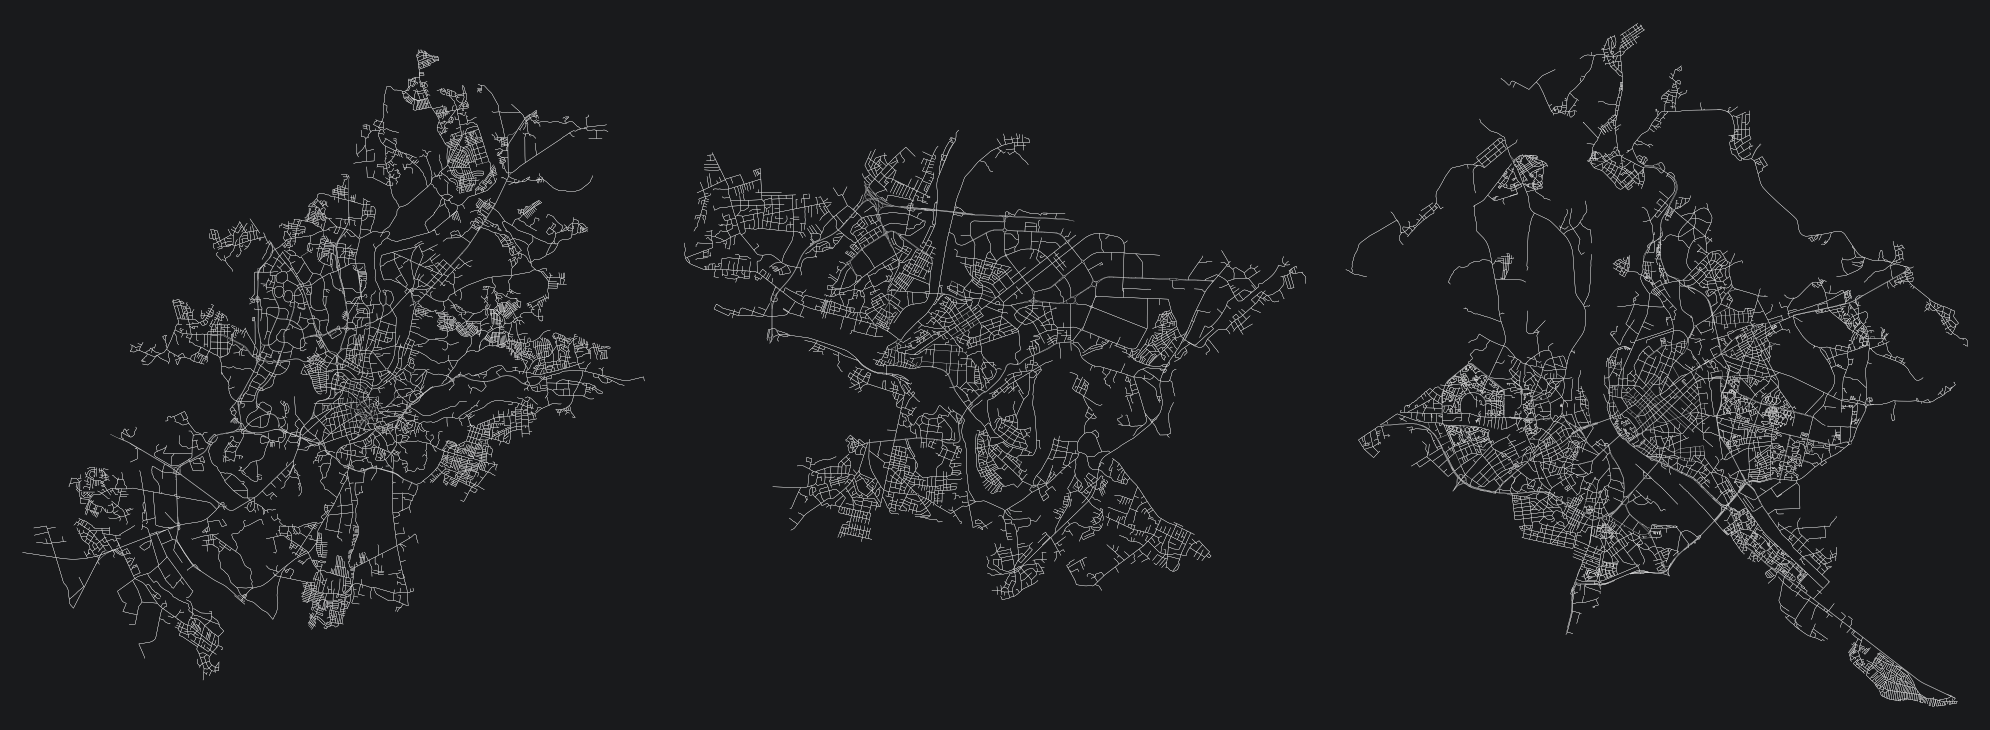

In [16]:
fig, axs = plt.subplots(1,3, figsize=(20,12))

for key, place in enumerate(places):
    ox.plot_graph(place.G, node_size=0, edge_color="w", edge_linewidth=0.2, ax=axs[key], show=False)

plt.tight_layout()
plt.show()